# Heatmap (Revenue Transition Matrix)

## Исходные данные для построения

- датафрейм

In [7]:
revenue_matrix = pd.read_csv('revenue_matrix.csv')
revenue_matrix

,From,To,Revenue,Revenue_Change,Customers,Revenue_M,Revenue_Change_M,Revenue_Driver
0,Active,Active,7323667.0,317150.0,4211,7.323667,0.317150,Expansion
1,Active,At Risk,2864477.0,-164591.0,2113,2.864477,-0.164591,Contraction
2,Active,Loyal,1808909.0,668920.0,479,1.808909,0.668920,Expansion
3,At Risk,Active,742862.0,144261.0,436,0.742862,0.144261,Reactivation
4,At Risk,At Risk,5069889.0,-883654.0,4202,5.069889,-0.883654,Contraction
5,At Risk,Churn,0.0,-1510818.0,1446,0.000000,-1.510818,Churn
6,At Risk,Loyal,394206.0,91892.0,92,0.394206,0.091892,Reactivation
7,Churn,Active,116080.0,116080.0,105,0.116080,0.116080,Reactivation
8,Churn,Churn,0.0,0.0,2353,0.000000,0.000000,Churn
9,Churn,Loyal,2856.0,2856.0,1,0.002856,0.002856,Reactivation


## Код для построения

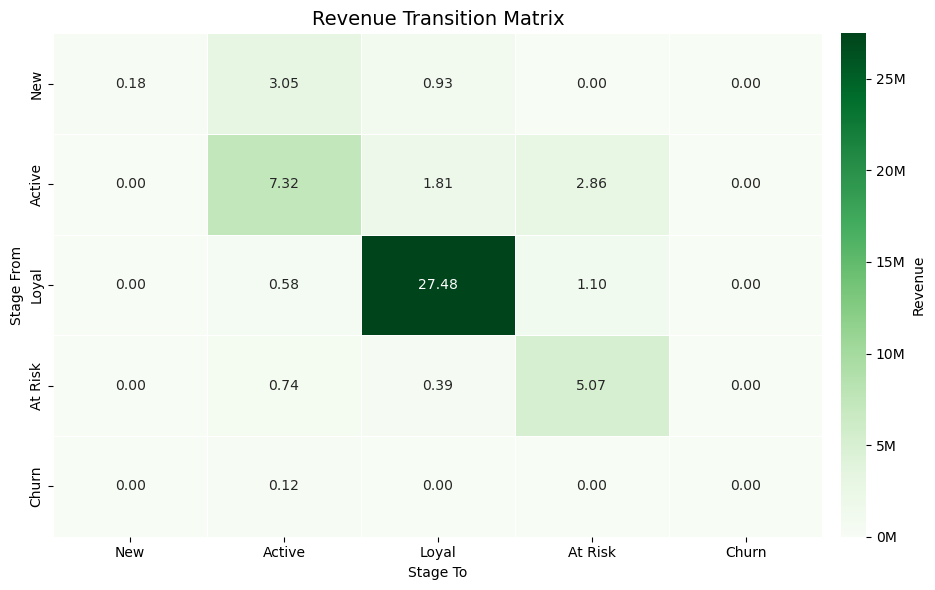

In [8]:
# =====================================================
# IMPORTS
# =====================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from matplotlib.ticker import FuncFormatter

# =====================================================
# LOAD DATA
# =====================================================

revenue_matrix = pd.read_csv('revenue_matrix.csv')

# =====================================================
# PREPARE DATA
# =====================================================

# Явно указать порядок следования стадий
stages = ['New', 'Active', 'Loyal', 'At Risk', 'Churn']

# Создаем pivot таблицу
revenue_flow_matrix = revenue_matrix.pivot(
    index='From',
    columns='To',
    values='Revenue_M'
).fillna(0)

# Явно задаем порядок следования стадий на графике
ordered_revenue_flow_matrix = revenue_flow_matrix.reindex(
    index=stages,
    columns=stages,
    fill_value=0
)

# =====================================================
# ПОСТРОЕНИЕ HEATMAP С ЯВНЫМ COLORBAR
# =====================================================

fig, ax = plt.subplots(figsize=(10, 6))

# Строим heatmap без colorbar
heatmap = sns.heatmap(
    ordered_revenue_flow_matrix,
    annot=True,
    fmt='.2f',
    cmap='Greens',
    linewidths=0.4,
    cbar=False  # ← отключаем автоматический colorbar
)

# =====================================================
# СОЗДАЕМ COLORBAR ВРУЧНУЮ
# =====================================================

# Параметр pad контролирует расстояние от графика
cbar = fig.colorbar(
    heatmap.get_children()[0], 
    ax=ax, 
    label='Revenue',
    pad=0.02#,           # ← УМЕНЬШАЕМ ОТСТУП
    #fraction=0.18,     # ← уменьшаем ширину colorbar
    #aspect=30           # ← соотношение сторон
)

# =====================================================
# ФОРМАТИРОВАНИЕ COLORBAR В ФОРМАТЕ "0M"
# =====================================================

def millions_formatter(x, pos):
    return f'{x:.0f}M'

cbar.ax.yaxis.set_major_formatter(FuncFormatter(millions_formatter))

# =====================================================
# УБИРАЕМ РАМКУ COLORBAR
# =====================================================

cbar.outline.set_visible(False)  # ← убираем черный контур!

# =====================================================
# ОФОРМЛЕНИЕ
# =====================================================

ax.set_title('Revenue Transition Matrix', fontsize=14)
ax.set_xlabel('Stage To')
ax.set_ylabel('Stage From')

# plt.tight_layout()
# plt.savefig("revenue_transition_matrix.png", dpi=300, bbox_inches="tight")

plt.show()